# 05 · Regression – predict the AQI value (same day)

**Task:** estimate the AQI of a city-day from that day's pollutant readings (features chosen in notebook 04: **PM2.5, PM10, CO, O3**).

| | |
|---|---|
| Baseline | **Linear Regression** (and a trivial *mean* predictor as the floor) |
| ML models | **Decision Tree · Random Forest · Gradient Boosting (HistGB, XGBoost-style) · Neural Network (MLP)** · XGBoost runs automatically if the package is installed |
| Tuning | `RandomizedSearchCV` + **time-series CV** (3 expanding folds) on the training period only, metric = MAE |
| Split | train 2015-01-01 → 2018-12-31 · **test 2019-01-01 → 2020-07-01** (never used for tuning or feature selection) |
| Metrics | MAE, RMSE, R² |

⚠ **Reading guide.** AQI is *computed* from the pollutants (CPCB: max of sub-indices), so a high R² is expected – this task is "learn the formula + the dataset's quirks". The harder and more useful task (forecasting tomorrow) is in notebook 07. As a reference we also score the CPCB formula itself (no ML).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import json, time, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.inspection import PartialDependenceDisplay
from sklearn.base import clone

from src import db, config, features, modeling, evaluate, cpcb
from src.config import LABELS, TEST_START, LOCKDOWN_START, CORE_CITIES
from src.viz import set_style, save_fig
set_style(); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

conn = db.get_conn()
df = pd.read_sql_query("SELECT * FROM aqi_features", conn, parse_dates=["date"])
pop = df[df.in_model_pop == 1].copy()
sel = json.load(open(config.RESULTS_DIR / "selected_features.json"))
NUM, CAT = sel["numeric"], sel["categorical"]
FEATS = NUM + CAT
FULL_NUM = features.MODEL_POLLUTANTS + features.CALENDAR_FEATURES + features.EVENT_FEATURES; FULL_CAT = features.CATEGORICAL_FEATURES

train, test = modeling.time_split(pop, TEST_START)
train = train.sort_values("date").reset_index(drop=True)          # sorted -> TimeSeriesSplit folds are chronological
test = test.sort_values(["date", "city"]).reset_index(drop=True)
lock = pd.Timestamp(LOCKDOWN_START)
print("selected features:", [LABELS[f] for f in FEATS])
print(f"train {len(train):,} rows  {train.date.min():%Y-%m-%d} → {train.date.max():%Y-%m-%d} | test {len(test):,} rows  {test.date.min():%Y-%m-%d} → {test.date.max():%Y-%m-%d}")
print("missing share of the 4 features in train:", train[NUM].isna().mean().mul(100).round(0).to_dict())

selected features: ['PM2.5', 'PM10', 'CO', 'O3']
train 12,541 rows  2015-01-01 → 2018-12-31 | test 10,959 rows  2019-01-01 → 2020-07-01
missing share of the 4 features in train: {'pm25': 3.0, 'pm10': 39.0, 'co': 4.0, 'o3': 2.0}


## 1 · Train and tune all models
Tree models (Decision Tree, Random Forest, HistGB) get the NaNs as they are; Linear Regression and the Neural Net get median imputation + scaling (fitted on the training data only) – see `src/modeling.py`.

In [2]:
catalog = modeling.regression_catalog()
if not modeling.HAS_XGB:
    print("(xgboost is not installed here – HistGradientBoosting, an equivalent histogram-based boosting model, is used; "
          "`pip install xgboost` adds an XGBoost row automatically)\n")
fitted, info = {}, {}
cv = TimeSeriesSplit(n_splits=3)
for name, spec in catalog.items():
    pipe, i = modeling.fit_model(name, spec, NUM, CAT, train[FEATS], train["aqi"], scoring="neg_mean_absolute_error", n_iter=6)
    if not np.isfinite(i["cv_score"]):          # models without a search space: compute CV score in the same way
        i["cv_score"] = cross_val_score(clone(pipe), train[FEATS], train["aqi"], cv=cv, scoring="neg_mean_absolute_error").mean()
    fitted[name], info[name] = pipe, i

(xgboost is not installed here – HistGradientBoosting, an equivalent histogram-based boosting model, is used; `pip install xgboost` adds an XGBoost row automatically)

  Mean (dummy)                 fitted in    0.0s   best params: -
  Linear Regression            fitted in    0.0s   best params: -
  Decision Tree                fitted in    0.5s   best params: {'min_samples_leaf': 20, 'max_depth': 14}
  Random Forest                fitted in   19.1s   best params: {'min_samples_leaf': 5, 'max_features': 0.8, 'max_depth': 12}
  Gradient Boosting (HistGB)   fitted in   10.0s   best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'learning_rate': 0.05, 'l2_regularization': 1.0}
  Neural Net (MLP)             fitted in    1.8s   best params: -


## 2 · Results – train, test, and before / during the lockdown

In [3]:
def eval_sets(pipe):
    out = {}
    pre, post = test[test.date < lock], test[test.date >= lock]
    for label, d in [("train", train), ("test", test), ("test_pre_lockdown", pre), ("test_lockdown", post)]:
        out[label] = evaluate.regression_metrics(d["aqi"], pipe.predict(d[FEATS]))
    return out

res, log_rows = {}, []
for name, pipe in fitted.items():
    res[name] = eval_sets(pipe)
    for es, m in res[name].items(): log_rows += evaluate.to_rows(name, "selected(4)", es, m)

# reference: the CPCB formula itself (no learning)
t2 = test.copy(); t2["aqi_cpcb"], _ = cpcb.reconstruct_aqi(t2); t2 = t2[t2.aqi_cpcb.notna()]
ref = evaluate.regression_metrics(t2["aqi"], t2["aqi_cpcb"])
print(f"Reference – CPCB formula applied to the raw pollutants (no ML), {len(t2):,}/{len(test):,} test rows: ", {k: round(v, 3) for k, v in ref.items()})

table = pd.DataFrame({n: {"CV MAE (train)": -info[n]["cv_score"], "train MAE": r["train"]["MAE"], "test MAE": r["test"]["MAE"],
                          "test RMSE": r["test"]["RMSE"], "test R2": r["test"]["R2"],
                          "R2 pre-lockdown": r["test_pre_lockdown"]["R2"], "R2 lockdown": r["test_lockdown"]["R2"],
                          "MAE pre-lockdown": r["test_pre_lockdown"]["MAE"], "MAE lockdown": r["test_lockdown"]["MAE"]} for n, r in res.items()}).T
table = table.sort_values("test MAE").round(3); table

Reference – CPCB formula applied to the raw pollutants (no ML), 10,959/10,959 test rows:  {'MAE': 18.395, 'RMSE': 27.932, 'R2': 0.889}


,CV MAE (train),train MAE,test MAE,test RMSE,test R2,R2 pre-lockdown,R2 lockdown,MAE pre-lockdown,MAE lockdown
Random Forest,25.385,18.589,15.962,25.733,0.906,0.907,0.747,16.525,13.875
Gradient Boosting (HistGB),26.435,20.395,16.052,25.413,0.908,0.910,0.750,16.589,14.063
Neural Net (MLP),24.947,22.529,16.338,24.726,0.913,0.915,0.748,16.880,14.334
Decision Tree,28.316,21.025,17.899,28.122,0.887,0.891,0.668,18.516,15.615
Linear Regression,33.773,32.638,22.373,31.887,0.855,0.855,0.660,23.473,18.301
Mean (dummy),95.743,90.448,82.893,95.147,-0.289,-0.141,-4.642,80.683,91.074


**How to read it.** *Train vs test* shows overfitting (a big gap = memorising); *CV MAE* is what we use to pick the best model **without** looking at the test set; the last columns split the test period into normal times and the lockdown (a regime the training data never saw). **Compare MAE, not R², across the two periods:** lockdown AQI values are low and vary little, so R² falls even when the absolute error does not.

best model by time-series CV (no test data used): Neural Net (MLP)


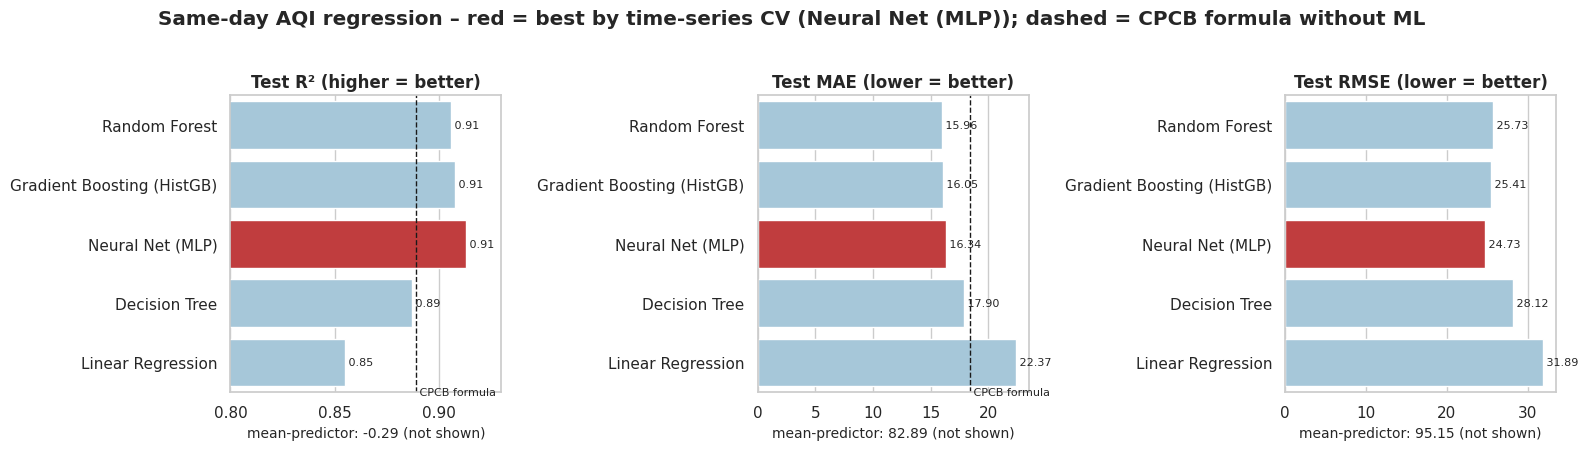

In [4]:
best_name = max((n for n in info if n != "Mean (dummy)"), key=lambda n: info[n]["cv_score"])     # chosen by CV on train only
print("best model by time-series CV (no test data used):", best_name)
best = fitted[best_name]; base = fitted["Linear Regression"]
order = [n for n in table.index if n != "Mean (dummy)"]
dummy = table.loc["Mean (dummy)"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, col, ttl in zip(axes, ["test R2", "test MAE", "test RMSE"], ["Test R² (higher = better)", "Test MAE (lower = better)", "Test RMSE (lower = better)"]):
    sns.barplot(x=table.loc[order, col], y=order, order=order, ax=ax, palette=["#d62728" if n == best_name else "#9ecae1" for n in order]); ax.set_title(ttl); ax.set_ylabel(""); ax.set_xlabel(f"mean-predictor: {dummy[col]:.2f} (not shown)")
    for i, n in enumerate(order): ax.text(table.loc[n, col], i, f" {table.loc[n, col]:.2f}", va="center", fontsize=8)
axes[0].set_xlim(0.80, 0.93); axes[0].axvline(ref["R2"], color="k", ls="--", lw=1); axes[0].text(ref["R2"], len(order) - 0.45, " CPCB formula", fontsize=8)
axes[1].axvline(ref["MAE"], color="k", ls="--", lw=1); axes[1].text(ref["MAE"], len(order) - 0.45, " CPCB formula", fontsize=8)
plt.suptitle(f"Same-day AQI regression – red = best by time-series CV ({best_name}); dashed = CPCB formula without ML", y=1.02, fontweight="bold")
plt.tight_layout(); save_fig("05_model_comparison"); plt.show()

### 2.1 Tuned hyper-parameters

In [5]:
pd.DataFrame({n: i["best_params"] for n, i in info.items() if i["best_params"]}).T.fillna("-")

,min_samples_leaf,max_depth,max_features,max_leaf_nodes,learning_rate,l2_regularization
Decision Tree,20.0,14.0,-,-,-,-
Random Forest,5.0,12.0,0.8,-,-,-
Gradient Boosting (HistGB),20.0,-,-,31.0,0.05,1.0


## 3 · Diagnostics for the baseline vs the best model

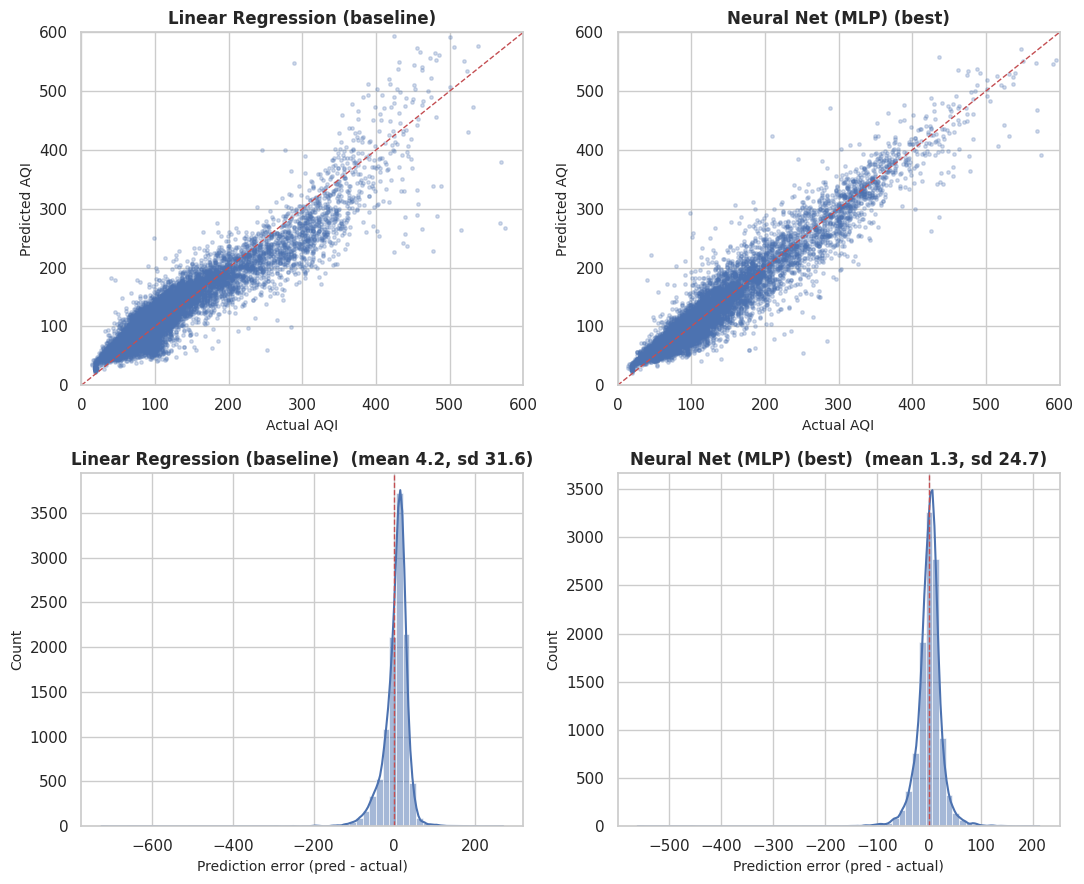

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for j, (nm, p) in enumerate([("Linear Regression (baseline)", base), (f"{best_name} (best)", best)]):
    pr = p.predict(test[FEATS])
    evaluate.plot_actual_vs_pred(test["aqi"], pr, nm, ax=axes[0, j], lim=600)
    evaluate.plot_residuals(test["aqi"], pr, nm, ax=axes[1, j])
plt.tight_layout(); save_fig("05_actual_vs_pred_residuals"); plt.show()

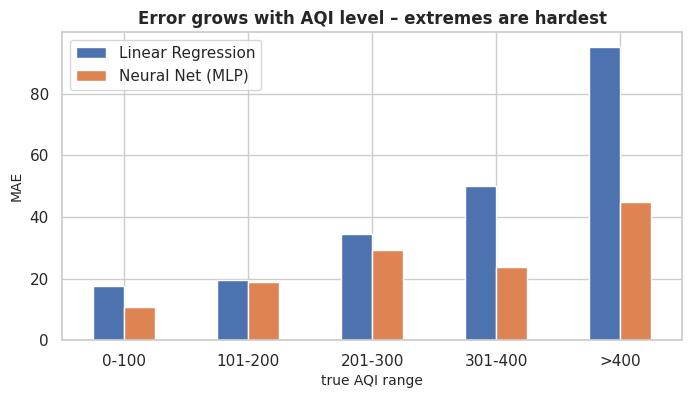

,Linear Regression,Neural Net (MLP),n_days
range,,,
0-100,17.7,10.8,5436
101-200,19.6,18.8,3872
201-300,34.5,29.4,983
301-400,50.1,23.7,538
>400,95.2,45.0,130


In [7]:
# error by AQI range: where do the models fail?
bins = [0, 100, 200, 300, 400, 2100]; labels_ = ["0-100", "101-200", "201-300", "301-400", ">400"]
test["range"] = pd.cut(test.aqi, bins=bins, labels=labels_)
e = pd.DataFrame({"Linear Regression": (base.predict(test[FEATS]) - test.aqi).abs(), best_name: (best.predict(test[FEATS]) - test.aqi).abs(), "range": test["range"]})
by_range = e.groupby("range").mean().round(1); by_range["n_days"] = test.groupby("range").size()
ax = by_range[["Linear Regression", best_name]].plot.bar(figsize=(8, 4), rot=0); ax.set_ylabel("MAE"); ax.set_xlabel("true AQI range"); ax.set_title("Error grows with AQI level – extremes are hardest")
save_fig("05_error_by_range"); plt.show(); by_range

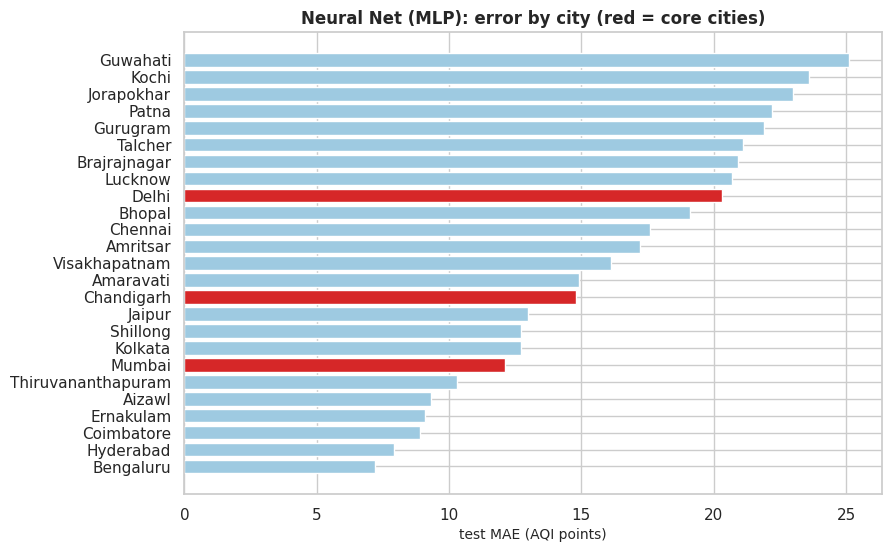

,n,MAE,mean_aqi,MAE_%_of_mean
city,,,,
Guwahati,495,25.1,140.1,17.9
Kochi,158,23.6,104.3,22.6
Jorapokhar,465,23.0,153.3,15.0
Patna,542,22.2,199.3,11.1
Gurugram,547,21.9,183.0,12.0
Talcher,459,21.1,166.2,12.7
Brajrajnagar,438,20.9,145.3,14.4
Lucknow,548,20.7,187.4,11.0
Delhi,548,20.3,215.3,9.4


In [8]:
pc = test.assign(pred=best.predict(test[FEATS]), abs_err=lambda d: (d.pred - d.aqi).abs())
city_err = pc.groupby("city").agg(n=("aqi", "size"), MAE=("abs_err", "mean"), mean_aqi=("aqi", "mean")); city_err["MAE_%_of_mean"] = (100 * city_err.MAE / city_err.mean_aqi).round(1)
city_err = city_err.sort_values("MAE", ascending=False).round(1)
fig, ax = plt.subplots(figsize=(9, 6)); ax.barh(city_err.index[::-1], city_err.MAE[::-1], color=["#d62728" if c in CORE_CITIES else "#9ecae1" for c in city_err.index[::-1]])
ax.set_xlabel("test MAE (AQI points)"); ax.set_title(f"{best_name}: error by city (red = core cities)"); save_fig("05_error_by_city"); plt.show(); city_err

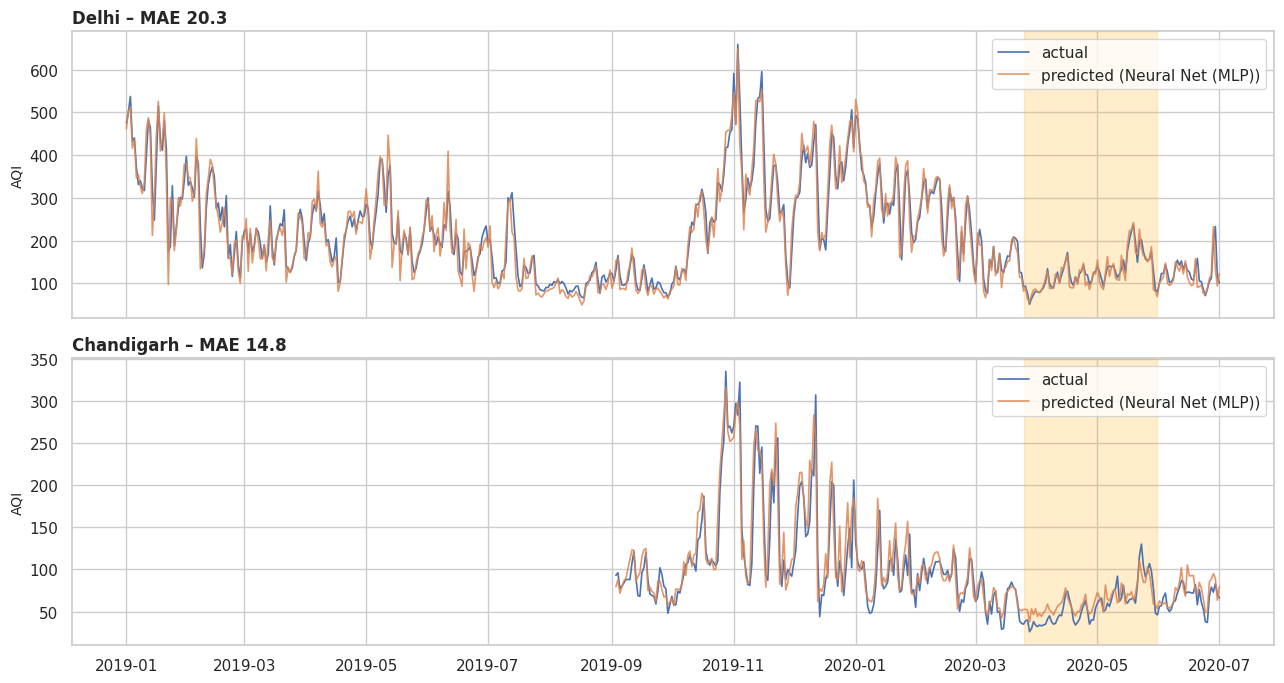

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for ax, c in zip(axes, ["Delhi", "Chandigarh"]):
    g = pc[pc.city == c].sort_values("date")
    ax.plot(g.date, g.aqi, label="actual", lw=1.2); ax.plot(g.date, g.pred, label=f"predicted ({best_name})", lw=1.2, alpha=0.85)
    ax.axvspan(lock, pd.Timestamp("2020-05-31"), color="orange", alpha=0.2); ax.set_ylabel("AQI"); ax.set_title(f"{c} – MAE {g.abs_err.mean():.1f}", loc="left"); ax.legend(loc="upper right")
plt.tight_layout(); save_fig("05_timeseries_pred_delhi_chandigarh"); plt.show()

### 3.1 What did the model learn? – partial dependence of AQI on each feature

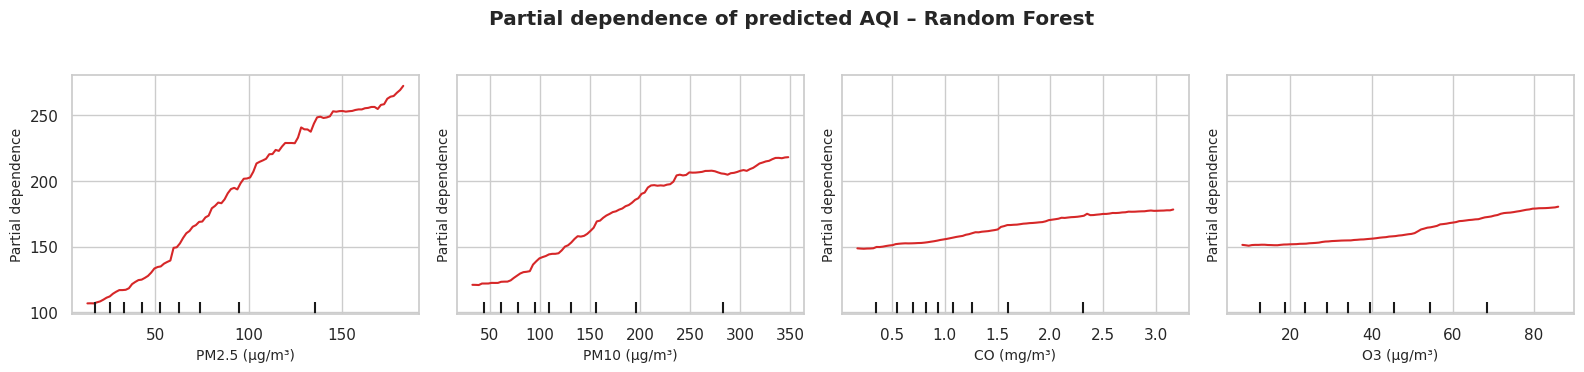

In [10]:
best_tree = max(["Decision Tree", "Random Forest", "Gradient Boosting (HistGB)"], key=lambda n: info[n]["cv_score"])
sample = train[FEATS].dropna().sample(2500, random_state=1)              # complete cases only, for a clean grid
fig, ax = plt.subplots(1, len(NUM), figsize=(4 * len(NUM), 3.6), sharey=True)
PartialDependenceDisplay.from_estimator(fitted[best_tree], sample, NUM, ax=ax, kind="average", line_kw={"color": "#d62728"})
for a_, f in zip(ax, NUM): a_.set_xlabel(LABELS[f] + (" (mg/m³)" if f == "co" else " (µg/m³)"))
plt.suptitle(f"Partial dependence of predicted AQI – {best_tree}", y=1.03, fontweight="bold"); plt.tight_layout(); save_fig("05_partial_dependence"); plt.show()

## 4 · Robustness checks
### 4.1 Full feature set (all 23 features) vs the 4 selected ones – same tuned hyper-parameters

In [11]:
rows = []
for name in ["Linear Regression", "Decision Tree", "Random Forest", "Gradient Boosting (HistGB)"]:
    spec = catalog[name]; est = clone(spec["est"]).set_params(**{k: v for k, v in info[name]["best_params"].items()})
    p = modeling.make_pipeline(est, FULL_NUM, FULL_CAT, spec["kind"]).fit(train[FULL_NUM + FULL_CAT], train["aqi"])
    m_full = evaluate.regression_metrics(test["aqi"], p.predict(test[FULL_NUM + FULL_CAT]))
    rows.append({"model": name, "R2 (4 features)": res[name]["test"]["R2"], "R2 (23 features)": m_full["R2"], "MAE (4 features)": res[name]["test"]["MAE"], "MAE (23 features)": m_full["MAE"]})
    log_rows += evaluate.to_rows(name, "full(23)", "test", m_full)
pd.DataFrame(rows).round(3)

,model,R2 (4 features),R2 (23 features),MAE (4 features),MAE (23 features)
0,Linear Regression,0.855,0.838,22.373,24.955
1,Decision Tree,0.887,0.878,17.899,18.796
2,Random Forest,0.906,0.909,15.962,15.536
3,Gradient Boosting (HistGB),0.908,0.912,16.052,16.073


### 4.2 Sensitivity to the suspect city (Ahmedabad)
Does including Ahmedabad in training change the results on the other cities – and can a model even learn Ahmedabad?

In [12]:
allp = df[df.valid_same_day == 1].copy()
tr_a, te_a = modeling.time_split(allp, TEST_START); tr_a = tr_a.sort_values("date")
rows = []
for name in ["Linear Regression", "Random Forest", "Gradient Boosting (HistGB)"]:
    spec = catalog[name]; est = clone(spec["est"]).set_params(**{k: v for k, v in info[name]["best_params"].items()})
    p = modeling.make_pipeline(est, NUM, CAT, spec["kind"]).fit(tr_a[FEATS], tr_a["aqi"])
    others, ahm = te_a[te_a.is_suspect == 0], te_a[te_a.is_suspect == 1]
    rows.append({"model": name,
                 "other cities: trained WITHOUT Ahmedabad (R2)": res[name]["test"]["R2"],
                 "other cities: trained WITH Ahmedabad (R2)": evaluate.regression_metrics(others.aqi, p.predict(others[FEATS]))["R2"],
                 "Ahmedabad itself (R2, model trained with it)": evaluate.regression_metrics(ahm.aqi, p.predict(ahm[FEATS]))["R2"],
                 "Ahmedabad MAE": evaluate.regression_metrics(ahm.aqi, p.predict(ahm[FEATS]))["MAE"]})
sens = pd.DataFrame(rows).round(3); sens

,model,other cities: trained WITHOUT Ahmedabad (R2),other cities: trained WITH Ahmedabad (R2),"Ahmedabad itself (R2, model trained with it)",Ahmedabad MAE
0,Linear Regression,0.855,0.855,0.731,83.359
1,Random Forest,0.906,0.905,0.746,85.589
2,Gradient Boosting (HistGB),0.908,0.908,0.724,91.474


### 4.3 Leakage check – shuffled-target sanity test
If the pipeline leaked test information, a model trained on *shuffled* AQI labels would still score above zero. It must not.

In [13]:
rng = np.random.default_rng(0)
shuf = clone(catalog["Gradient Boosting (HistGB)"]["est"]).set_params(**info["Gradient Boosting (HistGB)"]["best_params"])
p = modeling.make_pipeline(shuf, NUM, CAT, "tree").fit(train[FEATS], rng.permutation(train["aqi"].values))
print("R² on the test set of a model trained on shuffled targets:", round(evaluate.regression_metrics(test["aqi"], p.predict(test[FEATS]))["R2"], 3), "(should be ≈ 0 or negative)")

R² on the test set of a model trained on shuffled targets: -0.277 (should be ≈ 0 or negative)


## 5 · Save results

In [14]:
table.to_csv(config.RESULTS_DIR / "regression_same_day_results.csv")
by_range.to_csv(config.RESULTS_DIR / "regression_error_by_range.csv"); city_err.to_csv(config.RESULTS_DIR / "regression_error_by_city.csv"); sens.to_csv(config.RESULTS_DIR / "regression_ahmedabad_sensitivity.csv", index=False)
preds = test[["city", "date", "aqi"]].copy()
for n, p in fitted.items(): preds[n] = p.predict(test[FEATS]).round(1)
preds.to_csv(config.RESULTS_DIR / "regression_same_day_predictions.csv", index=False)
json.dump({"best_by_cv": best_name, "best_params": {n: {k: (None if v is None else (float(v) if isinstance(v, (np.floating,)) else (int(v) if isinstance(v, np.integer) else v))) for k, v in i["best_params"].items()} for n, i in info.items()},
           "cpcb_formula_reference": ref}, open(config.RESULTS_DIR / "regression_best_params.json", "w"), indent=2)
db.log_results(log_rows + evaluate.to_rows("CPCB formula (no ML)", "raw pollutants", "test", ref), "regression_same_day", conn); conn.close()
config.MODELS_DIR.mkdir(exist_ok=True)
for nm in dict.fromkeys(["Linear Regression", best_name, "Gradient Boosting (HistGB)"]):
    path = config.MODELS_DIR / f"regression_{nm.split(' (')[0].lower().replace(' ', '_')}.joblib"
    joblib.dump(fitted[nm], path, compress=3); print(f"saved {path.relative_to(ROOT)}  ({path.stat().st_size / 1e6:.2f} MB)")

saved models/regression_linear_regression.joblib  (0.00 MB)
saved models/regression_neural_net.joblib  (0.06 MB)
saved models/regression_gradient_boosting.joblib  (0.19 MB)


## 6 · Conclusions – same-day regression

| Model | Test MAE | Test RMSE | Test R² |
|---|---|---|---|
| Mean predictor (floor) | 82.9 | 95.1 | −0.29 |
| **Linear Regression (baseline)** | 22.4 | 31.9 | 0.855 |
| Decision Tree | 17.9 | 28.1 | 0.887 |
| Random Forest | **15.96** | 25.7 | 0.906 |
| Gradient Boosting (HistGB) | 16.05 | 25.4 | 0.908 |
| Neural Net (MLP) | 16.3 | **24.7** | **0.913** |
| *Reference: CPCB formula, no ML* | 18.4 | 27.9 | 0.889 |

1. **Every ML model beats the baseline**, and the non-linear ones cut the MAE by ≈ 28 % (22.4 → 16.0). The relationship between PM and AQI is piecewise-linear and a *max* over pollutants – a straight line cannot represent it, trees and the neural net can.
2. **The top three (Random Forest, Gradient Boosting, Neural Net) are practically tied** (R² 0.906–0.913, MAE 16.0–16.3). Chosen by time-series CV on the training data (no test peeking), the best is the **Neural Net (lowest CV MAE)**; Random Forest has the lowest test MAE. Differences at this level are within noise – we would not claim one is "the" winner.
3. **The ML models even beat the official CPCB formula applied to the raw pollutants** (MAE 16.0 vs 18.4): the dataset's AQI was produced with 24-h / 8-h averaged inputs we do not have, and the models learn that calibration.
4. **Errors grow with the AQI level** (Linear Regression: MAE ≈ 18 for AQI < 100 vs ≈ 95 above 400; the non-linear models cut the high-end error by about half). Extreme episodes are rare and hardest.
5. **Error differs by city:** Delhi MAE 20 (≈ 9 % of its mean AQI), Mumbai 12, Chandigarh 15 (≈ 15 %), Bengaluru 7. Chandigarh was *never seen in training* (its data starts in Sept 2019), yet its error is in line with the other cities: the pollutant → AQI mapping transfers across cities.
6. **No sign of overfitting:** test MAE is actually *lower* than train MAE for every model (e.g. Random Forest 16.0 vs 18.6) because the training years 2015–2018 were more polluted and noisier (higher AQI → larger absolute errors). The CV MAE (≈ 25, validated on the *later* part of each fold's history) is the more pessimistic estimate for the older years.
7. **Lockdown period:** R² falls to ≈ 0.75, but the **MAE actually falls (≈ 14 vs ≈ 16.5)** – lockdown AQI is low and varies little, so the same absolute error is a larger share of the (smaller) variance. The model generalises to a regime it never saw.
8. **Feature reduction is validated:** with all 23 features, Random Forest / Gradient Boosting gain only +0.003–0.004 R² and the linear model gets *worse* (0.838 vs 0.855) – 4 features are enough.
9. **Ahmedabad:** adding it to the training data changes nothing for other cities (R² identical to 3 decimals) while the model cannot predict Ahmedabad itself (R² ≈ 0.73, MAE ≈ 85) – consistent with its data being unreliable.
10. **No leakage:** a model trained on shuffled labels scores R² = −0.28 on the test set.

**Limitation:** same-day regression is largely "AQI formula learning". Predicting the *future* is the harder, more useful problem → notebook 07.